In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Set text. Requires a LaTeX installation for usetex=True.
plt.rcParams.update(
    {
        'text.usetex': True,
        'font.family': 'serif',
        'font.serif': ['Computer Modern Roman'],
        'font.size': 13,
        'axes.linewidth': 0.8,
        'savefig.bbox': 'tight',
    }
)


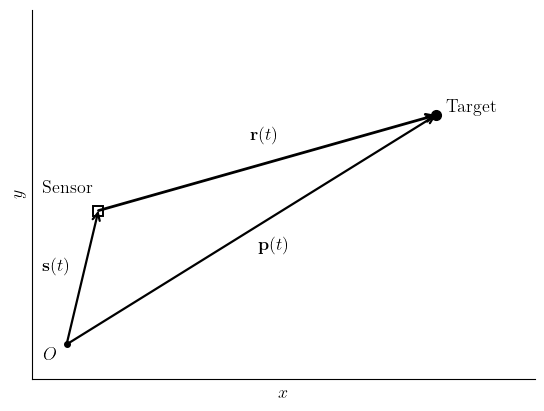

In [2]:
s = np.array([0.5, 2.1])
p = np.array([5.8, 3.6])
r = p - s
fig, ax = plt.subplots(figsize=(7, 4.8))


def arrow(start, delta, label, offset=(0, 0), lw=1.6):
    ax.annotate(
        '',
        xy=start + delta,
        xytext=start,
        arrowprops={
            'arrowstyle': '->',
            'color': 'black',
            'lw': lw,
            'shrinkA': 0,
            'shrinkB': 0,
            'mutation_scale': 13,
        },
    )
    middle = start + 0.5 * delta + np.array(offset)
    ax.text(*middle, label, ha='center', va='center')


origin = np.zeros(2)
arrow(origin, s, r'$\mathbf{s}(t)$', (-0.42, 0.16))
arrow(origin, p, r'$\mathbf{p}(t)$', (0.35, -0.25))
arrow(s, r, r'$\mathbf{r}(t)$', (-0.05, 0.43), lw=2.0)

ax.plot(*origin, 'ko', ms=4)
ax.plot(*s, 'ks', ms=7, mfc='white', mew=1.4)
ax.plot(*p, 'ko', ms=7)
ax.text(-0.16, -0.24, r'$O$', ha='right')
ax.text(s[0] - 0.1, s[1] + 0.28, 'Sensor', ha='right')
ax.text(p[0] + 0.16, p[1] + 0.04, 'Target', ha='left')

ax.set(xlim=(-0.55, 7.35), ylim=(-0.55, 5.25), xlabel=r'$x$', ylabel=r'$y$')
ax.set_aspect('equal', adjustable='box')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])
fig.savefig('./figures/tma_relative_position.png', dpi=220)
plt.show()
plt.close(fig)

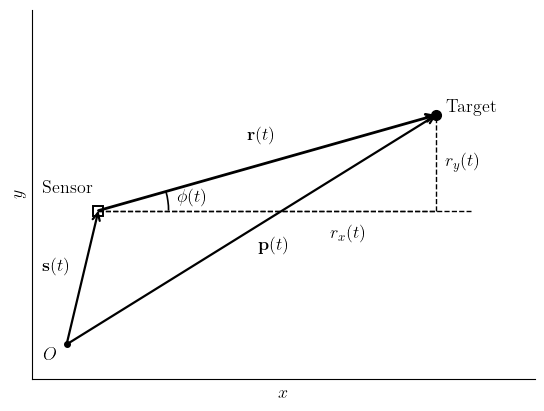

In [3]:
from matplotlib.patches import Arc

# Assumes your rcParams already enable:
# plt.rcParams['text.usetex'] = True
# plt.rcParams['font.family'] = 'serif'

s = np.array([0.5, 2.1])
p = np.array([5.8, 3.6])
r = p - s
phi = np.arctan2(r[1], r[0])

fig, ax = plt.subplots(figsize=(7, 4.8))


def arrow(start, delta, label, offset=(0, 0), lw=1.6):
    ax.annotate(
        '',
        xy=start + delta,
        xytext=start,
        arrowprops={
            'arrowstyle': '->',
            'color': 'black',
            'lw': lw,
            'shrinkA': 0,
            'shrinkB': 0,
            'mutation_scale': 13,
        },
    )
    middle = start + 0.5 * delta + np.array(offset)
    ax.text(*middle, label, ha='center', va='center')


origin = np.zeros(2)

# Main vectors
arrow(origin, s, r'$\mathbf{s}(t)$', (-0.42, 0.16))
arrow(origin, p, r'$\mathbf{p}(t)$', (0.35, -0.25))
arrow(s, r, r'$\mathbf{r}(t)$', (-0.10, 0.43), lw=2.0)

# Points
ax.plot(*origin, 'ko', ms=4)
ax.plot(*s, 'ks', ms=7, mfc='white', mew=1.4)
ax.plot(*p, 'ko', ms=7)

# Labels
ax.text(-0.16, -0.24, r'$O$', ha='right')
ax.text(s[0] - 0.1, s[1] + 0.28, 'Sensor', ha='right')
ax.text(p[0] + 0.16, p[1] + 0.04, 'Target', ha='left')

# Dashed horizontal reference ray from the sensor
x_ref_end = p[0] + 0.55
ax.plot([s[0], x_ref_end], [s[1], s[1]], 'k--', lw=1.0)

# Dashed projection lines showing r_x and r_y
proj = np.array([p[0], s[1]])
ax.plot([s[0], proj[0]], [s[1], proj[1]], 'k--', lw=1.0)
ax.plot([proj[0], p[0]], [proj[1], p[1]], 'k--', lw=1.0)

# Optional labels for components
ax.text(
    0.7 * (s[0] + proj[0]), s[1] - 0.22, r'$r_x(t)$', ha='center', va='top'
)
ax.text(
    p[0] + 0.14, 0.5 * (proj[1] + p[1]), r'$r_y(t)$', ha='left', va='center'
)

# Angle arc for phi(t)
arc_radius = 1.1
arc = Arc(
    s,
    width=2 * arc_radius,
    height=2 * arc_radius,
    angle=0,
    theta1=0,
    theta2=np.degrees(phi),
    lw=1.2,
    color='black',
)
ax.add_patch(arc)

# Label for phi(t)
phi_label_radius = 1.35
phi_label_pos = s + phi_label_radius * np.array(
    [1.1 * np.cos(phi / 2), 1.1 * np.sin(phi / 2)]
)
ax.text(
    phi_label_pos[0], phi_label_pos[1], r'$\phi(t)$', ha='center', va='center'
)

# Axes styling
ax.set(xlim=(-0.55, 7.35), ylim=(-0.55, 5.25), xlabel=r'$x$', ylabel=r'$y$')
ax.set_aspect('equal', adjustable='box')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])

fig.savefig('./figures/tma_azimuth_geometry.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)

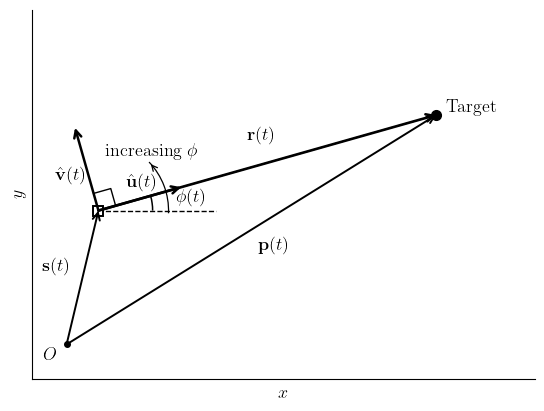

In [4]:
# Assumes rcParams already set, e.g.
# plt.rcParams['text.usetex'] = True
# plt.rcParams['font.family'] = 'serif'

s = np.array([0.5, 2.1])
p = np.array([5.8, 3.6])
r = p - s
phi = np.arctan2(r[1], r[0])

u_hat = r / np.linalg.norm(r)
v_hat = np.array([-u_hat[1], u_hat[0]])

fig, ax = plt.subplots(figsize=(7.2, 4.8))


def arrow(start, delta, label=None, offset=(0, 0), lw=1.6, ms=13):
    ax.annotate(
        '',
        xy=start + delta,
        xytext=start,
        arrowprops={
            'arrowstyle': '->',
            'color': 'black',
            'lw': lw,
            'shrinkA': 0,
            'shrinkB': 0,
            'mutation_scale': ms,
        },
    )
    if label is not None:
        middle = start + 0.5 * delta + np.array(offset)
        ax.text(*middle, label, ha='center', va='center')


origin = np.zeros(2)

# Main geometry
arrow(origin, s, r'$\mathbf{s}(t)$', (-0.42, 0.16), lw=1.4)
arrow(origin, p, r'$\mathbf{p}(t)$', (0.35, -0.25), lw=1.4)
arrow(s, r, r'$\mathbf{r}(t)$', (-0.10, 0.43), lw=1.9)

# LOS line
ax.plot([s[0], p[0]], [s[1], p[1]], 'k--', lw=1.0)

# Local LOS-transverse frame at the sensor
frame_scale = 1.35
arrow(
    s,
    frame_scale * u_hat,
    r'$\hat{\mathbf{u}}(t)$',
    offset=(0.03, 0.25),
    lw=1.8,
)
arrow(
    s,
    frame_scale * v_hat,
    r'$\hat{\mathbf{v}}(t)$',
    offset=(-0.25, -0.1),
    lw=1.8,
)

# Right-angle marker between u_hat and v_hat
corner = s + 0.28 * u_hat
corner2 = corner + 0.28 * v_hat
corner3 = s + 0.28 * v_hat
ax.plot(
    [corner[0], corner2[0], corner3[0]],
    [corner[1], corner2[1], corner3[1]],
    'k-',
    lw=1.0,
)

# Dashed +x reference line for azimuth
x_ref_end = s + np.array([1.85, 0.0])
ax.plot([s[0], x_ref_end[0]], [s[1], x_ref_end[1]], 'k--', lw=1.0)

# Azimuth arc
arc_radius = 0.85
arc = Arc(
    s,
    width=2 * arc_radius,
    height=2 * arc_radius,
    angle=0,
    theta1=0,
    theta2=np.degrees(phi),
    lw=1.1,
    color='black',
)
ax.add_patch(arc)

phi_label_radius = 1.05
phi_label_pos = s + phi_label_radius * np.array(
    [1.4 * np.cos(phi / 2), 1.4 * np.sin(phi / 2)]
)
ax.text(
    phi_label_pos[0], phi_label_pos[1], r'$\phi(t)$', ha='center', va='center'
)

# Small curved indication that +v is the direction of increasing azimuth
inc_radius = 1.1
inc_arc = Arc(
    s,
    width=2 * inc_radius,
    height=2 * inc_radius,
    angle=0,
    theta1=np.degrees(phi) - 18,
    theta2=np.degrees(phi) + 28,
    lw=0.9,
    color='black',
)
ax.add_patch(inc_arc)

# Tiny arrowhead at end of increasing-phi arc
theta_end = phi + np.deg2rad(28)
theta_prev = theta_end - np.deg2rad(7)
pt_end = s + inc_radius * np.array([np.cos(theta_end), np.sin(theta_end)])
pt_prev = s + inc_radius * np.array([np.cos(theta_prev), np.sin(theta_prev)])
ax.annotate(
    '',
    xy=pt_end,
    xytext=pt_prev,
    arrowprops={
        'arrowstyle': '->',
        'color': 'black',
        'lw': 0.9,
        'mutation_scale': 10,
    },
)

ax.text(s[0] + 0.1, s[1] + 0.8, r'increasing $\phi$', ha='left', va='bottom')

# Points and labels
ax.plot(*origin, 'ko', ms=4)
ax.plot(*s, 'ks', ms=7, mfc='white', mew=1.4)
ax.plot(*p, 'ko', ms=7)

ax.text(-0.16, -0.24, r'$O$', ha='right')
ax.text(p[0] + 0.16, p[1] + 0.04, 'Target', ha='left')

# Axes styling
ax.set(xlim=(-0.55, 7.35), ylim=(-0.55, 5.25), xlabel=r'$x$', ylabel=r'$y$')
ax.set_aspect('equal', adjustable='box')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])

fig.savefig('./figures/tma_ltf_frame.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)

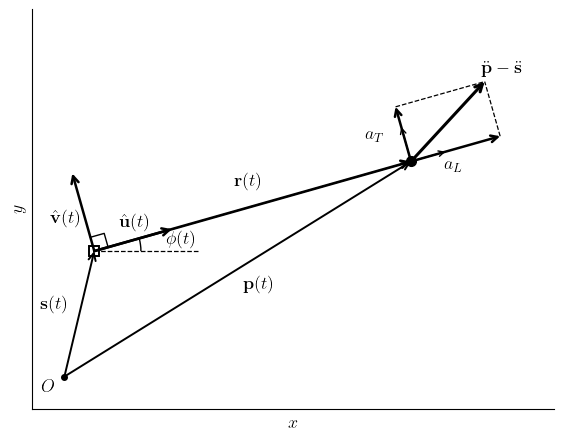

In [5]:
# Assumes rcParams already set, e.g.
# plt.rcParams['text.usetex'] = True
# plt.rcParams['font.family'] = 'serif'

s = np.array([0.5, 2.1])
p = np.array([5.8, 3.6])
r = p - s
phi = np.arctan2(r[1], r[0])

u_hat = r / np.linalg.norm(r)
v_hat = np.array([-u_hat[1], u_hat[0]])

# Illustrative relative-acceleration components in the LTF
a_los_mag = 1.55
a_trn_mag = 0.95

a_los = a_los_mag * u_hat
a_trn = a_trn_mag * v_hat
a_rel = a_los + a_trn

fig, ax = plt.subplots(figsize=(7.4, 5.2))


def arrow(start, delta, label=None, offset=(0.0, 0.0), lw=1.6, ms=13):
    ax.annotate(
        '',
        xy=start + delta,
        xytext=start,
        arrowprops={
            'arrowstyle': '->',
            'color': 'black',
            'lw': lw,
            'shrinkA': 0,
            'shrinkB': 0,
            'mutation_scale': ms,
        },
    )
    if label is not None:
        mid = start + 0.5 * delta + np.array(offset)
        ax.text(*mid, label, ha='center', va='center')


origin = np.zeros(2)

# Main geometry
arrow(origin, s, r'$\mathbf{s}(t)$', offset=(-0.42, 0.16), lw=1.4)
arrow(origin, p, r'$\mathbf{p}(t)$', offset=(0.35, -0.25), lw=1.4)
arrow(s, r, r'$\mathbf{r}(t)$', offset=(-0.08, 0.42), lw=1.9)

# LOS line
ax.plot([s[0], p[0]], [s[1], p[1]], 'k--', lw=1.0)
# ax.text(
#     s[0] + 0.72 * r[0],
#     s[1] + 0.72 * r[1] - 0.18,
#     'LOS',
#     ha='center',
#     va='top'
# )

# Local basis at the sensor
frame_scale = 1.35
arrow(
    s,
    frame_scale * u_hat,
    r'$\hat{\mathbf{u}}(t)$',
    offset=(0.03, 0.3),
    lw=1.8,
)
arrow(
    s,
    frame_scale * v_hat,
    r'$\hat{\mathbf{v}}(t)$',
    offset=(-0.3, -0.1),
    lw=1.8,
)

# Right-angle marker for LTF
corner = s + 0.24 * u_hat
corner2 = corner + 0.24 * v_hat
corner3 = s + 0.24 * v_hat
ax.plot(
    [corner[0], corner2[0], corner3[0]],
    [corner[1], corner2[1], corner3[1]],
    'k-',
    lw=1.0,
)

# Dashed +x reference line and azimuth arc
x_ref_end = s + np.array([1.75, 0.0])
ax.plot([s[0], x_ref_end[0]], [s[1], x_ref_end[1]], 'k--', lw=0.9)

arc_radius = 0.78
arc = Arc(
    s,
    width=2 * arc_radius,
    height=2 * arc_radius,
    angle=0,
    theta1=0,
    theta2=np.degrees(phi),
    lw=1.0,
    color='black',
)
ax.add_patch(arc)

phi_label_radius = 0.98
phi_label_pos = s + phi_label_radius * np.array(
    [1.5 * np.cos(phi / 2), 1.5 * np.sin(phi / 2)]
)
ax.text(
    phi_label_pos[0], phi_label_pos[1], r'$\phi(t)$', ha='center', va='center'
)

# Relative acceleration decomposition at the target
# Draw components from the target point
arrow(
    p,
    a_los,
    r'$a_L$',
    offset=(-0.05, -0.25),
    lw=1.8,
    ms=12,
)

arrow(
    p,
    a_trn,
    r'$a_T$',
    offset=(-0.5, 0.0),
    lw=1.8,
    ms=12,
)

# Total relative acceleration from the target point
arrow(
    p,
    a_rel,
    r'$\ddot{\mathbf{p}}-\ddot{\mathbf{s}}$',
    offset=(0.9, 0.9),
    lw=2.2,
    ms=13,
)

# Dashed component-addition guides (parallelogram style)
ax.plot(
    [p[0] + a_los[0], p[0] + a_rel[0]],
    [p[1] + a_los[1], p[1] + a_rel[1]],
    'k--',
    lw=0.9,
)
ax.plot(
    [p[0] + a_trn[0], p[0] + a_rel[0]],
    [p[1] + a_trn[1], p[1] + a_rel[1]],
    'k--',
    lw=0.9,
)

# Small basis arrows at the target to reinforce projection directions
mini_scale = 0.6
arrow(p, mini_scale * u_hat, None, lw=1.0, ms=10)
arrow(p, mini_scale * v_hat, None, lw=1.0, ms=10)

# Labels for scalar LOS/transverse acceleration terms
los_text_pos = p + 0.56 * a_los + np.array([0.12, -0.34])
trn_text_pos = p + 0.58 * a_trn + np.array([-0.14, 0.16])

# ax.text(
#     *los_text_pos, r'$\ddot{\rho}-\rho\dot{\phi}^{2}$', ha='left', va='top'
# )
# ax.text(
#     *trn_text_pos,
#     r'$2\dot{\rho}\dot{\phi}+\rho\ddot{\phi}$',
#     ha='left',
#     va='bottom',
# )

# Points and labels
ax.plot(*origin, 'ko', ms=4)
ax.plot(*s, 'ks', ms=7, mfc='white', mew=1.4)
ax.plot(*p, 'ko', ms=7)

ax.text(-0.16, -0.24, r'$O$', ha='right')
# ax.text(s[0] - 0.1, s[1] + 0.28, 'Sensor', ha='right')
# ax.text(p[0] + 0.16, p[1] + 0.04, 'Target', ha='left')

# Axes styling
ax.set(xlim=(-0.55, 8.2), ylim=(-0.55, 6.15), xlabel=r'$x$', ylabel=r'$y$')
ax.set_aspect('equal', adjustable='box')
ax.spines[['top', 'right']].set_visible(False)
ax.set_xticks([])
ax.set_yticks([])

fig.savefig(
    './figures/tma_los_transverse_acceleration.png',
    dpi=220,
    bbox_inches='tight',
)
plt.show()
plt.close(fig)

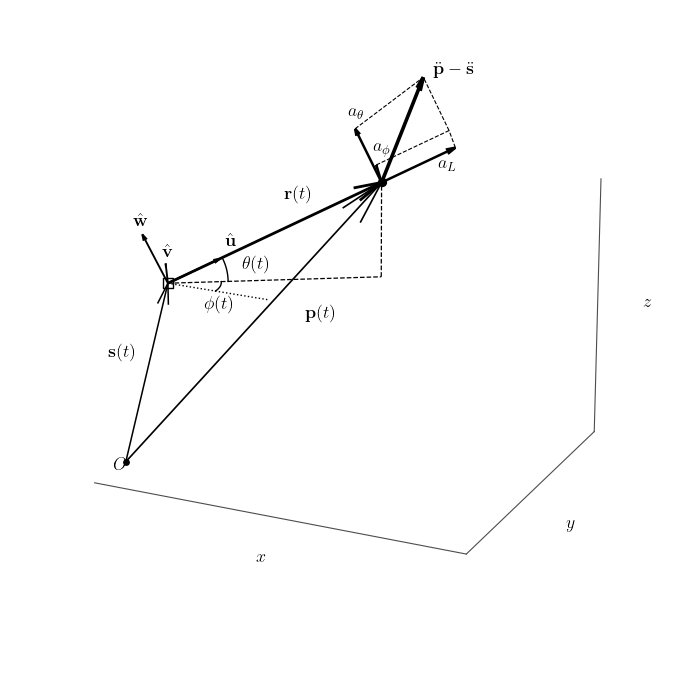

In [ ]:
# Sensor, target, and spherical LOS angles (elevation above xy plane).
s = np.array([0.7, 0.8, 4])
phi = np.deg2rad(30.0)
theta = np.deg2rad(25.0)
rho = 5.1
u_hat = np.array(
    [np.cos(theta) * np.cos(phi), np.cos(theta) * np.sin(phi), np.sin(theta)]
)
v_hat = np.array([-np.sin(phi), np.cos(phi), 0.0])  # increasing azimuth
w_hat = np.array(
    [-np.sin(theta) * np.cos(phi), -np.sin(theta) * np.sin(phi), np.cos(theta)]
)  # increasing elevation
p = s + rho * u_hat

# Illustrative signed scalar components of relative acceleration.
a_L, a_phi, a_theta = 1.75, 1.20, 1.35
A = a_L * u_hat
B = a_phi * v_hat
C = a_theta * w_hat
a_rel = A + B + C

fig = plt.figure(figsize=(9.0, 6.8))
ax = fig.add_subplot(111, projection='3d', computed_zorder=False)


def arrow(start, delta, lw=1.6, mutation=12):
    # 3D arrows using quiver, with consistent monochrome styling.
    ax.quiver(
        *start,
        *delta,
        color='k',
        linewidth=lw,
        arrow_length_ratio=0.12,
        normalize=False,
    )


def label(pos, value, offset=(0, 0, 0), **kwargs):
    ax.text(
        *(np.asarray(pos) + np.asarray(offset)), value, color='k', **kwargs
    )


O = np.zeros(3)
arrow(O, s, lw=1.1)
arrow(O, p, lw=1.2)
arrow(s, p - s, lw=2.0)
label(0.55 * s, r'$\mathbf{s}(t)$', offset=(-1, 0.0, 0.0))
label(0.58 * p, r'$\mathbf{p}(t)$', offset=(1, -0.48, -0.06))
label(s + 0.58 * (p - s), r'$\mathbf{r}(t)$', offset=(-0.25, 0.15, 0.5))

# Cartesian azimuth plane and elevation reference.
q = np.array([p[0], p[1], s[2]])
ax.plot([s[0], q[0]], [s[1], q[1]], [s[2], q[2]], 'k--', lw=0.9)
ax.plot([q[0], p[0]], [q[1], p[1]], [q[2], p[2]], 'k--', lw=0.9)
ax.plot([s[0], s[0] + 2.4], [s[1], s[1]], [s[2], s[2]], 'k:', lw=1)
ang = np.linspace(0, phi, 60)
rad = 1.15
arc = s + rad * np.column_stack([np.cos(ang), np.sin(ang), np.zeros_like(ang)])
ax.plot(*arc.T, 'k-', lw=1)
label(
    s + 1.48 * np.array([np.cos(phi / 2), np.sin(phi / 2) - 1, 0]),
    r'$\phi(t)$',
)
ang2 = np.linspace(0, theta, 60)
rad2 = 1.30
arc2 = s + rad2 * np.column_stack(
    [np.cos(ang2) * np.cos(phi), np.cos(ang2) * np.sin(phi), np.sin(ang2)]
)
ax.plot(*arc2.T, 'k-', lw=1)
label(
    s
    + 1.68
    * np.array(
        [
            np.cos(theta / 2) * np.cos(phi),
            np.cos(theta / 2) * np.sin(phi),
            np.sin(theta / 2),
        ]
    ),
    r'$\theta(t)$',
    offset=(0.0, -0.08, -0.07),
)

# Local orthonormal LOS, azimuth, and elevation basis at sensor.
frame_scale = 1.25
for basis in [u_hat, v_hat, w_hat]:
    arrow(s, frame_scale * basis, lw=1.35)
label(s + 1.36 * u_hat, r'$\hat{\mathbf{u}}$', offset=(0.0, 0.0, 0.25))
label(s + 1.47 * v_hat, r'$\hat{\mathbf{v}}$', offset=(-0.10, 0.05, 0.06))
label(s + 1.35 * w_hat, r'$\hat{\mathbf{w}}$', offset=(-0.2, 0.05, 0.08))

# Acceleration vector decomposition at target.
for component in [A, B, C]:
    arrow(p, component, lw=1.8)
arrow(p, a_rel, lw=2.6)
# Dashed construction path for A + B + C and closure guides.
for start, end in [
    (p + A, p + A + B),
    (p + A + B, p + a_rel),
    (p + B, p + A + B),
    (p + C, p + a_rel),
]:
    ax.plot(*np.array([start, end]).T, 'k--', lw=0.8)
label(p + 0.70 * A, r'$a_L$', offset=(0.25, -0.30, -0.10))
label(p + 0.72 * B, r'$a_\phi$', offset=(-0.12, 0.03, 0.4))
label(p + 0.68 * C, r'$a_\theta$', offset=(-0.4, 0.05, 0.6))
label(
    p + 0.94 * a_rel,
    r'$\ddot{\mathbf{p}}-\ddot{\mathbf{s}}$',
    offset=(0.23, 0.10, 0.22),
)

ax.scatter(*O, color='k', s=15, depthshade=False)
ax.scatter(
    *s, color='white', edgecolors='black', marker='s', s=52, depthshade=False
)
ax.scatter(*p, color='k', s=32, depthshade=False)
label(O, r'$O$', offset=(-0.2, -0.22, -0.13))
ax.set(
    xlim=(-0.4, 8.4),
    ylim=(-0.7, 6.6),
    zlim=(-0.3, 5.7),
    xlabel=r'$x$',
    ylabel=r'$y$',
    zlabel=r'$z$',
)
ax.set_box_aspect((8.8, 7.3, 6.0), zoom=0.87)
ax.view_init(elev=21, azim=-65)
ax.grid(False)
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.pane.fill = False
    axis.pane.set_edgecolor('white')
    axis.line.set_color('0.3')
    axis.set_ticks([])
ax.dist = 10
fig.subplots_adjust(left=0.0, right=0.96, bottom=0.02, top=0.99)
fig.savefig('./figures/tma_3d_acceleration.png', dpi=220, bbox_inches='tight')
plt.show()
plt.close(fig)
